Maximum Likelihood Estimate of mu: 0.23625046125711407


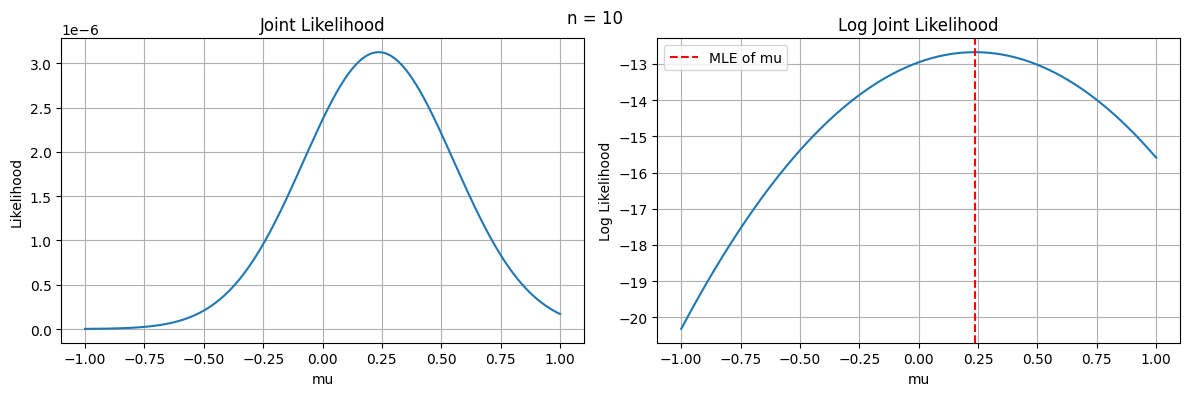

In [19]:
# generate n samples from normal distribution with mean mu and standard deviation sigma
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
from scipy.optimize import minimize


def generate_samples(n, mu, sigma):
    return np.random.normal(mu, sigma, n)

n = 10
mu, sigma = 0, 1
x = generate_samples(n, mu, sigma)

# create a def for the joint likelihood function
def joint_likelihood(mu, sigma, x):
    n = len(x)
    likelihood = norm.pdf(x, mu, sigma).prod()
    return likelihood

# create a def for the log joint likelihood function
def log_joint_likelihood(mu, sigma, x):
    n = len(x)
    log_likelihood = np.sum(norm.logpdf(x, mu, sigma))
    return log_likelihood

def neg_log_likelihood(mu):
    return -log_joint_likelihood(mu, 1, x)

# fix sigma=1 and plot the joint likelihood function for different values of mu
mu_values = np.linspace(-1, 1, 1000)

result = minimize(neg_log_likelihood, x0=0, method='BFGS')
mle_mu = result.x[0]
print("Maximum Likelihood Estimate of mu: {}".format(mle_mu))
# plot a 1x2 grid of subplots to show the joint likelihood and log joint likelihood functions
plt.figure(figsize=(12, 4))

# First subplot: Joint Likelihood
plt.subplot(1, 2, 1)
plt.plot(mu_values, [joint_likelihood(mu, 1, x) for mu in mu_values])
plt.xlabel('mu')
plt.ylabel('Likelihood')
plt.title('Joint Likelihood')
plt.grid()

# Second subplot: Log Joint Likelihood
plt.subplot(1, 2, 2)
plt.plot(mu_values, [log_joint_likelihood(mu, 1, x) for mu in mu_values])
# draw a vertical line at the maximum likelihood estimate of mu
plt.axvline(mle_mu, color='r', linestyle='--', label='MLE of mu')
plt.xlabel('mu')
plt.ylabel('Log Likelihood')
plt.title('Log Joint Likelihood')
plt.grid()
plt.tight_layout()
plt.legend()
plt.suptitle('n = {}'.format(n))
plt.show()

# compute the maximum likelihood estimate of mu by maximizing the log joint likelihood function




